# Интеграция пользовательского детектора в пайплайн

Пример для Manuscript OCR 0.1.13 на модели [Daniil-Domino/yolo11x-text-detection](https://huggingface.co/Daniil-Domino/yolo11x-text-detection).

Подключим YOLO через собственный класс: он запускает модель и превращает найденные области в `Page`. Таким же способом можно подключить другой детектор.

В Manuscript уже есть класс `YOLO` для ONNX-моделей. Здесь используем Ultralytics, чтобы показать устройство пользовательского адаптера. В конце приведён вариант с готовым классом и экспортом.

## 1. Установка


In [1]:
%pip install "manuscript-ocr[cpu]==0.1.13" "ultralytics==8.4.176" huggingface-hub



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Пользовательский детектор

Пайплайн вызывает `predict(image)` и ожидает `Page` либо словарь с ключом `page`. В нашем примере возвращается сама страница. Наследоваться от базового класса необязательно.

Адаптер отвечает за размеры страницы, геометрию и тип найденных элементов. Здесь области записываются как слова; для модели строк выберите `region_type="line"` и соответствующий распознаватель. Сортировку и группировку оставляем этапу лейаута.


In [2]:
from pathlib import Path

from PIL import Image
from IPython.display import display
from ultralytics import YOLO as UltralyticsYOLO
from huggingface_hub import hf_hub_download

from manuscript.data import Page, TextRegion
from manuscript.utils.io import read_image


class CustomYOLO:
    """Адаптер детектора: predict принимает снимок и возвращает разметку Page."""

    def __init__(self, weights, conf=0.25, iou=0.7, imgsz=640, device="cpu", region_type="word"):
        if region_type not in ("word", "line", "block"):
            raise ValueError("region_type: выберите word, line или block")
        # Здесь загрузите свою модель и сохраните её параметры инференса.
        self.model = UltralyticsYOLO(str(weights))
        self.conf = conf
        self.iou = iou
        self.imgsz = imgsz
        self.device = device
        self.region_type = region_type

    def predict(self, image) -> Page:
        # read_image принимает путь, PIL.Image или массив и возвращает RGB.
        pixels = read_image(image)
        height, width = pixels.shape[:2]
        page = Page(image_width=width, image_height=height)

        # Замените этот участок вызовом своего детектора.
        # Ultralytics принимает массивы в BGR, поэтому меняем порядок каналов.
        result = self.model.predict(
            pixels[:, :, ::-1].copy(),
            conf=self.conf, iou=self.iou, imgsz=self.imgsz,
            device=self.device, verbose=False,
        )[0]
        if result.boxes is None:
            return page  # Отсутствие находок — корректная пустая страница.

        for box in result.boxes:
            # Координаты xyxy уже относятся к исходному снимку, а не входу модели.
            x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()
            polygon = ((x1, y1), (x2, y1), (x2, y2), (x1, y2))
            region = TextRegion(
                type=self.region_type,
                polygon=polygon,
                detection_confidence=float(box.conf[0].item()),
            )
            # Привязка родителя включит область в дерево страницы.
            # Для модели с несколькими классами задайте тип по box.cls.
            region.parent = page

        # Верните Page с геометрией; текст запишет следующий этап распознавания.
        return page


/Users/user/manuscript-ocr/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Модель и изображение

Загрузим веса и покажем страницу `example/images/full/img2.jpeg`.


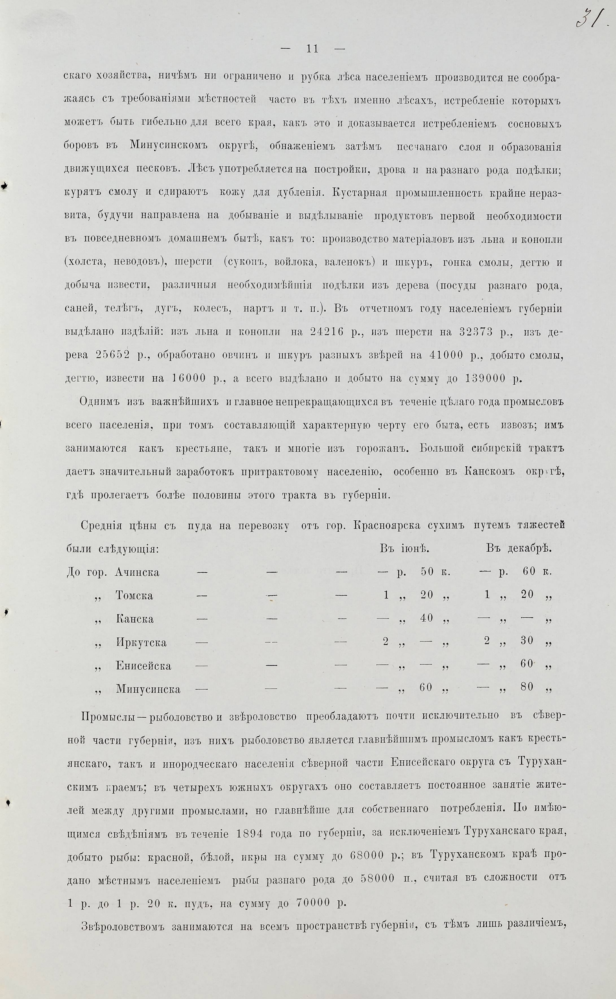

In [3]:
model_path = hf_hub_download(
    repo_id="Daniil-Domino/yolo11x-text-detection",
    filename="model.pt",
)
detector = CustomYOLO(weights=model_path, device="cpu", region_type="word")

PROJECT_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file()),
    Path.cwd(),
)
image_path = PROJECT_DIR / "example/images/full/img2.jpeg"
if not image_path.exists():
    from urllib.request import urlretrieve
    image_path.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(
        "https://raw.githubusercontent.com/konstantinkozhin/manuscript-ocr/"
        "4193d8a613a7cfdec6a68cd2cdbb88b351f63964/example/images/img2.jpeg",
        image_path,
    )

image = Image.open(image_path).convert("RGB")
display(image)


## 4. Подключение к пайплайну

Наш детектор создаёт слова, `SimpleSorting` собирает строки и определяет порядок чтения. TRBA распознаёт слова, а CharLM исправляет их текст.


хозяйства, ничѣмъ ни ограничено рубка чѣса населенiемъ производится не сообраз
которыхъ
быть гибельно для гибельно края. доказывается стребленiемъ сосновыхъ
боровъ въ Минусинскомъ округѣ обнаженiемъ затѣмъ образованiя
движущихся пескова Лѣсъ употребляется на пост ройки. дрова и на разнаго на ра: наго рода подѣлки;
курять смолу сдираютъ кожу для дубленiя Кустарная промышленность крайне нераз
вита. будучи направлена на добыванiе выдѣлыванiе родуктовъ первой необходимости
въ повседневному ломашнемъ бытѣ. какъ производство материаловъ и льна конопли
(холста. неводовъ), шерсти суконъ войлока. валенокъ окъ) и шкуръ. шкуръ. тонка смол дегтю
добыча извести. различная необходимѣйшiя подѣлки дерева (посуды разнаго рода,
саней телѣгъ дугъ, колесо, нартъ п.). Въ отчетномъ году населенiемъ губернiи
выдѣлано издѣ издѣлiй iй: изъ льна и конопли на 24216 р., изъ шерсти на 32373 р., изъ де-
дева 25652 р., обработано ОВЧИНЪ и шкуръ разныхъ звѣрей на 41000 р., добыто смолы.
дегтю, извести на 16000 р., вс

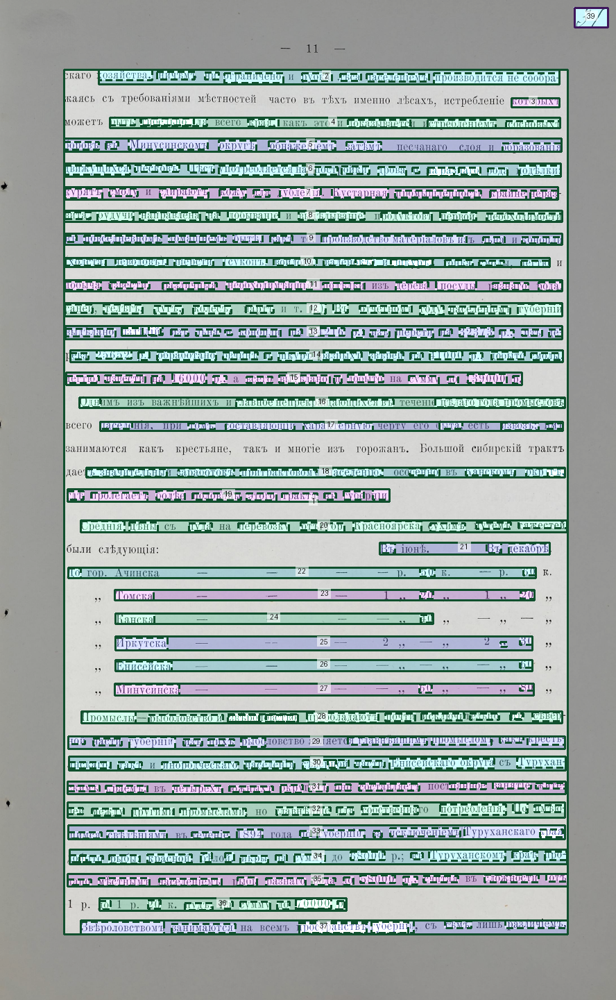

In [4]:
from manuscript import Pipeline
from manuscript.layouts import SimpleSorting
from manuscript.recognizers import TRBA
from manuscript.correctors import CharLM
from manuscript.utils.visualization import visualize_page

pipeline = Pipeline(
    detector=detector,  # Наш пользовательский адаптер YOLO.
    layout=SimpleSorting(),
    recognizer=TRBA(weights="trba_lite_g1", device="cpu"),
    corrector=CharLM(weights="modern_charlm_g1", device="cpu"),
)
result = pipeline.predict(image)
page = result["page"]  # Пайплайн возвращает словарь результатов.

print(page.get_text())
display(visualize_page(image, page, max_size=1440, upscale=True))


## 5. Альтернатива: готовый YOLO из Manuscript

Модель можно экспортировать скриптом [scripts/export_yolo.py](../../scripts/export_yolo.py), который создаёт ONNX и JSON-конфиг. Из корня репозитория запустите команду, указав путь к скачанному `model.pt`:

```bash
python scripts/export_yolo.py /путь/к/model.pt models/custom_yolo/model.onnx --region-type word
```

Вместо пользовательского адаптера подключите готовый детектор:

```python
from manuscript.detectors import YOLO

detector = YOLO(
    weights="models/custom_yolo/model.onnx",
    config="models/custom_yolo/model.json",
    device="cpu",
)
```

Для работы нужны оба файла: ONNX содержит модель, JSON задаёт параметры и типы областей. Детектор передаётся в `Pipeline` тем же параметром `detector`.
